# Asset Pricing — Kernel, Constrained (Uno)

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

This notebook solves the same problem as the companion ridgeless
notebook, but with a **constrained optimizer**: the interior-point
solver [Uno](https://github.com/cvanaret/Uno) through `unopy`, with JAX
supplying the gradient, Jacobian, and Hessian callbacks. Structural
parameters stay plain module-level constants — the NLP solver is
host-side C++, so nothing rides through a differentiable `p` here.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import unopy

Structural parameters of the economic model.

In [2]:
r = 0.1  # interest rate
c = 0.02  # dividend flow constant
g = -0.2  # dividend growth rate
x_0 = 0.01  # initial dividend

Parameters of the algorithm: the kernel hyperparameters and the
collocation and test grids.

In [3]:
ELL = 10.0  # Matern-1/2 length scale
SIGMA = 1.0  # kernel amplitude
TRAIN_T = 40.0
N_TRAIN = 41
TEST_T = 50.0
N_TEST = 100

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)

## The model

An asset pays the deterministic dividend flow

$$x(t) = \left(x_0 + \frac{c}{g}\right) e^{g t} - \frac{c}{g},$$

and no-arbitrage at interest rate $r$ prices it by the linear ODE
$p'(t) = r\, p(t) - x(t)$. Every solution is the fundamental price plus
a bubble $\zeta e^{rt}$; as in the ridgeless notebook we impose no
boundary condition — the minimum-norm selection below rules out the
explosive mode, with the initial price $p_0$ a free unknown.

## The integrated kernel

The hypothesis class is an RKHS built from the Matérn-1/2 kernel applied
to the *derivative* of the price path,

$$k(t, t') = \sigma^2 e^{-|t - t'|/\ell},
\qquad
h(d) = \sigma^2 \ell \left(1 - e^{-d/\ell}\right),
\qquad
\tilde K(t_i, t_j) = h(t_j) + \operatorname{sign}(t_i - t_j)\, h(|t_i - t_j|),$$

so that $p(t) = p_0 + \sum_j \alpha_j \tilde K(t, t_j)$ with the exact
derivative $p'(t) = \sum_j \alpha_j k(t, t_j)$, and
$\tilde K(0, \cdot) = 0$ makes $p_0$ the initial price.

In [4]:
def antiderivative(d):
    return SIGMA**2 * ELL * (1.0 - jnp.exp(-d / ELL))


def kernel_matrices(t_i, t_j):
    s = t_i[:, None] - t_j[None, :]
    K = SIGMA**2 * jnp.exp(-jnp.abs(s) / ELL)
    K_tilde = antiderivative(t_j)[None, :] + jnp.sign(s) * antiderivative(jnp.abs(s))
    return K, K_tilde


def dividends(t):
    return (x_0 + c / g) * jnp.exp(g * t) - c / g

## The constrained program

The ridgeless notebook reaches the minimum-norm interpolant as the
$\lambda \to 0$ limit of the penalized least squares
$\min \|r\|^2 + \lambda\, \alpha^\top K \alpha$. The
constrained-optimizer implementation solves that limit **exactly**, as
the nonlinear program

$$\min_{\alpha,\, p_0}\ \alpha^\top K \alpha
\quad \text{s.t.} \quad
p'(t_i) - \big(r\, p(t_i) - x(t_i)\big) = 0 \quad \text{at every training date,}$$

handing objective, constraints, and their derivatives — `jax.grad`,
[`jax.jacfwd`](https://docs.jax.dev/en/latest/automatic-differentiation.html),
and the Hessian of the Lagrangian via `jax.hessian` — to the
interior-point solver as jitted callbacks.

In [5]:
K, K_tilde = kernel_matrices(t_train, t_train)

N_VARIABLES = N_TRAIN + 1
N_CONSTRAINTS = N_TRAIN


def unpack(x):
    return x[:N_TRAIN], x[N_TRAIN]


@jax.jit
def objective(x):
    alpha, _ = unpack(x)
    return alpha @ K @ alpha


@jax.jit
def constraints(x):
    alpha, p_0 = unpack(x)
    price = p_0 + K_tilde @ alpha
    return K @ alpha - (r * price - dividends(t_train))


def lagrangian(x, objective_multiplier, multipliers):
    return objective_multiplier * objective(x) + multipliers @ constraints(x)


objective_gradient = jax.jit(jax.grad(objective))
constraint_jacobian = jax.jit(jax.jacfwd(constraints))
lagrangian_hessian = jax.jit(jax.hessian(lagrangian, argnums=0))

## The NLP setup

Uno takes the problem in sparse-triplet form; with a dense kernel model
the Jacobian is simply every (row, column) pair and the Hessian its
lower triangle.

In [6]:
variable_lower_bounds = np.full(N_VARIABLES, -np.inf)
variable_upper_bounds = np.full(N_VARIABLES, np.inf)
model = unopy.Model(
    unopy.PROBLEM_QUADRATIC,
    N_VARIABLES,
    variable_lower_bounds,
    variable_upper_bounds,
    unopy.ZERO_BASED_INDEXING,
)


def objective_callback(x):
    return float(objective(jnp.asarray(x)))


def objective_gradient_callback(x, gradient):
    gradient[:] = np.asarray(objective_gradient(jnp.asarray(x)))


model.set_objective(unopy.MINIMIZE, objective_callback, objective_gradient_callback)

jacobian_rows = np.repeat(np.arange(N_CONSTRAINTS, dtype=np.int32), N_VARIABLES)
jacobian_columns = np.tile(np.arange(N_VARIABLES, dtype=np.int32), N_CONSTRAINTS)


def constraints_callback(x, constraint_output):
    constraint_output[:] = np.asarray(constraints(jnp.asarray(x)))


def jacobian_callback(x, jacobian_output):
    jacobian_output[:] = np.asarray(constraint_jacobian(jnp.asarray(x))).reshape(-1)


model.set_constraints(
    N_CONSTRAINTS,
    constraints_callback,
    np.zeros(N_CONSTRAINTS),
    np.zeros(N_CONSTRAINTS),
    len(jacobian_rows),
    jacobian_rows,
    jacobian_columns,
    jacobian_callback,
)

hessian_rows, hessian_columns = (
    idx.astype(np.int32) for idx in np.tril_indices(N_VARIABLES)
)


def hessian_callback(x, objective_multiplier, multipliers, hessian_output):
    hessian = np.asarray(
        lagrangian_hessian(
            jnp.asarray(x), float(objective_multiplier), jnp.asarray(multipliers)
        )
    )
    hessian_output[:] = hessian[hessian_rows, hessian_columns]


model.set_lagrangian_hessian(
    len(hessian_rows),
    unopy.LOWER_TRIANGLE,
    hessian_rows,
    hessian_columns,
    hessian_callback,
)
model.set_lagrangian_sign_convention(unopy.MULTIPLIER_POSITIVE)
model.set_initial_primal_iterate(np.zeros(N_VARIABLES))

## Solve

The `ipopt` preset reproduces the classic filter line-search
interior-point method.

In [7]:
solver = unopy.UnoSolver()
solver.set_preset("ipopt")
solver.set_option("logger", "SILENT")
solver.set_option("print_solution", False)

start = time.perf_counter()
result = solver.optimize(model)
solve_time = time.perf_counter() - start

x = jnp.asarray(np.array(result.primal_solution))
alpha, p_0 = unpack(x)

## Results

Identical diagnostics to the ridgeless notebook: the no-arbitrage
residual on the test grid (extending past the training horizon), the
learned $p_0$ against the closed-form fundamental $p_f(0) = 0.7$, and
the relative pricing error against

$$p_f(t) = \frac{x_0 + c/g}{r - g}\, e^{g t} - \frac{c}{g r}.$$

In [8]:
K_test, K_tilde_test = kernel_matrices(t_test, t_train)
price_test = p_0 + K_tilde_test @ alpha
test_residual = K_test @ alpha - (r * price_test - dividends(t_test))

# Closed-form fundamental (no-bubble) price.
price_fundamental = (x_0 + c / g) * jnp.exp(g * t_test) / (r - g) - c / (g * r)
rel_error = jnp.abs(price_test - price_fundamental) / price_fundamental

print(f"solve: {result.solution_status.name} in {solve_time:.2f}s (incl. jit)")
print(f"p_0 = {float(p_0):.6f}")
print(f"max |test residual|: {float(jnp.max(jnp.abs(test_residual))):.3e}")
print(f"max rel error vs fundamental: {float(jnp.max(rel_error)):.3e}")

solve: FEASIBLE_KKT_POINT in 0.12s (incl. jit)
p_0 = 0.699498
max |test residual|: 2.035e-04
max rel error vs fundamental: 7.178e-04

The constrained solution tracks the closed-form fundamental with no
bubble, degrading only as it extrapolates past the training horizon
(dotted).

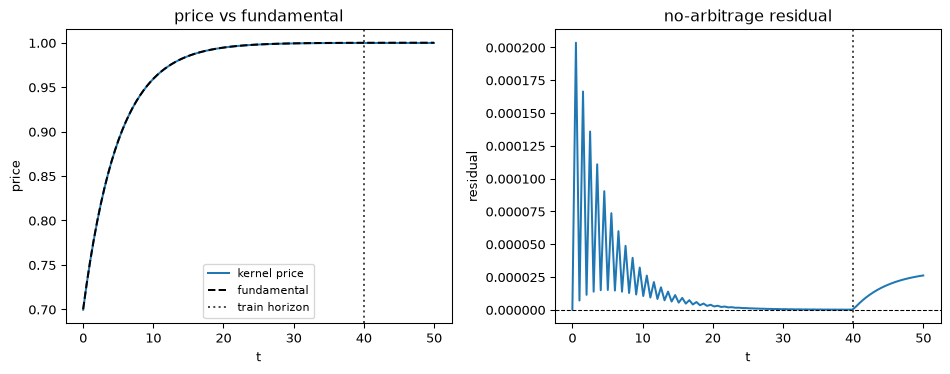

In [9]:
fig, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_p.plot(t_test, price_test, "C0", label="kernel price")
ax_p.plot(t_test, price_fundamental, "k--", label="fundamental")
ax_p.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_p.set(xlabel="t", ylabel="price", title="price vs fundamental")
ax_p.legend(fontsize=8)
ax_r.plot(t_test, test_residual, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="no-arbitrage residual")
fig.tight_layout()
plt.show()